
# 02. Data Preparation & Feature Engineering

## 1. Business Objective & Prediction Framework

FinGuard AI aims to identify potentially fraudulent financial transactions before they are executed, enabling risk-based investigation and intervention.

### Prediction timing

The fraud detection model operates at the **pre-transaction decision point**. Therefore, only information available before transaction execution can be used as predictive input.

Post-transaction account balances and existing fraud detection flags are excluded from the initial feature set to minimize data leakage and support a realistic inference workflow.

### Data preparation objectives

- Define a leakage-aware feature set.
- Establish chronological training, validation, and test partitions.
- Preserve the original class distribution for reliable evaluation.
- Implement reproducible preprocessing transformations.
- Prepare the foundation for transaction-level and historical feature engineering.

### Evaluation principles

Model development will prioritize precision-recall metrics, operational alert volume, and performance on unseen future transactions rather than accuracy alone.



## 2. Dataset Loading & Temporal Inspection

The PaySim dataset contains simulated financial transactions recorded across sequential hourly time steps.

Before creating the training, validation, and test datasets, we examine the temporal coverage and fraud distribution.

A chronological split is preferred over a random split because it more closely represents a real-world fraud detection scenario: models are trained on historical transactions and evaluated on future activity.

However, temporal distribution shifts must be considered to ensure that the resulting evaluation remains meaningful.


In [21]:

from pathlib import Path

import pandas as pd

DATA_PATH = Path("../data/raw/paysim.csv")

df = pd.read_csv(
    DATA_PATH,
    usecols=["step", "type", "amount",
             "oldbalanceOrg", "newbalanceOrig",
             "oldbalanceDest", "newbalanceDest",
             "nameOrig", "nameDest",
             "isFraud", "isFlaggedFraud"]
)

print(f"Dataset shape: {df.shape}")
print(f"Time range: {df['step'].min()}–{df['step'].max()}")
print(f"Fraud cases: {df['isFraud'].sum():,}")


Dataset shape: (6362620, 11)
Time range: 1–743
Fraud cases: 8,213


In [22]:

df["simulation_day"] = ((df["step"] - 1) // 24) + 1

daily_summary = (
    df.groupby("simulation_day")["isFraud"]
    .agg(
        transactions="count",
        fraud_cases="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

daily_summary["fraud_rate_pct"] = (
    daily_summary["fraud_rate"] * 100
)

display(
    daily_summary[
        ["simulation_day", "transactions",
         "fraud_cases", "fraud_rate_pct"]
    ].tail(12)
)


,simulation_day,transactions,fraud_cases,fraud_rate_pct
19,20,19727,236,1.196330
20,21,24593,272,1.106006
21,22,53437,256,0.479069
22,23,51012,216,0.423430
23,24,32709,280,0.856034
24,25,57853,240,0.414845
25,26,13885,272,1.958949
26,27,8578,280,3.264164
27,28,14661,248,1.691563
28,29,54890,260,0.473675



**Findings**

These observations confirm substantial temporal variation in transaction volume and fraud prevalence, reinforcing the need for a chronological splitting strategy. The anomalous behavior observed on day 31 also motivates a separate sensitivity analysis during final model evaluation.

- **Transaction volume varies considerably over time**, ranging from 8,578 transactions on day 27 to 57,853 on day 25 within the displayed period.
- **Fraud prevalence fluctuates significantly**, reaching 3.26% on day 27, compared with 0.41% on day 25.
- **Fraud counts remain relatively stable** across most displayed days, while changes in transaction volume contribute to substantial variations in fraud rates.
- **Day 31 presents a clear anomaly:** all 272 recorded transactions are fraudulent, resulting in a 100% fraud rate.

These observations suggest temporal distribution shifts and highlight the importance of evaluating the final day separately when interpreting test performance.



### 2.1. Temporal Distribution Findings

The PaySim dataset exhibits substantial temporal variation in transaction volume and fraud prevalence.

Key observations:

- Transaction volumes fluctuate considerably during the later simulation periods.
- Fraud prevalence increases on several days as legitimate transaction activity declines.
- The final simulation day contains only 272 transactions, all labeled as fraudulent.
- A conventional chronological split may therefore produce evaluation partitions with substantially different class distributions.

**Modeling implication:** Temporal partitions must be inspected before model training. The final simulation period should not be silently discarded or treated as representative of normal transaction activity.

A primary chronological evaluation and a separate temporal robustness analysis will help distinguish predictive performance from dataset-specific distribution shifts.


In [23]:

def summarize_period(start_day, end_day):
    subset = daily_summary.loc[
        daily_summary["simulation_day"].between(start_day, end_day)
    ]

    transactions = int(subset["transactions"].sum())
    fraud_cases = int(subset["fraud_cases"].sum())

    return {
        "period": f"Days {start_day}–{end_day}",
        "transactions": transactions,
        "fraud_cases": fraud_cases,
        "fraud_rate_pct": (
            100 * fraud_cases / transactions
            if transactions > 0 else 0
        ),
    }


split_candidates = {
    "A": [(1, 20), (21, 25), (26, 31)],
    "B": [(1, 23), (24, 27), (28, 31)],
    "C": [(1, 20), (21, 25), (26, 30)],
}

rows = []

for candidate, periods in split_candidates.items():
    for partition, (start, end) in zip(
        ["Train", "Validation", "Test"], periods
    ):
        rows.append({
            "candidate": candidate,
            "partition": partition,
            **summarize_period(start, end),
        })

split_comparison = pd.DataFrame(rows)

display(split_comparison)


,candidate,partition,period,transactions,fraud_cases,fraud_rate_pct
0,A,Train,Days 1–20,6039443,5349,0.088568
1,A,Validation,Days 21–25,219604,1264,0.575582
2,A,Test,Days 26–31,103573,1600,1.544804
3,B,Train,Days 1–23,6168485,6093,0.098776
4,B,Validation,Days 24–27,113025,1072,0.948463
5,B,Test,Days 28–31,81110,1048,1.292072
6,C,Train,Days 1–20,6039443,5349,0.088568
7,C,Validation,Days 21–25,219604,1264,0.575582
8,C,Test,Days 26–30,103301,1328,1.285564



**Findings — Chronological Split Comparison**

- **Candidate A** preserves the complete dataset, with 6,039,443 training transactions, 219,604 validation transactions, and 103,573 test transactions.
- **Candidate B** extends the training period to day 23, reducing the validation sample to 113,025 transactions and increasing its fraud prevalence to 0.95%.
- **Candidate C** retains the same training and validation partitions as Candidate A but excludes the anomalous final day from testing.
- **All candidates exhibit temporal distribution shifts**, with fraud prevalence increasing substantially between training and evaluation periods.
- **Candidate A provides the primary evaluation framework**, while Candidate C offers a complementary sensitivity analysis to assess the influence of day 31.

**Modeling Decision:** Candidate A is selected for the primary chronological split (Train: days 1–20; Validation: days 21–25; Test: days 26–31). Test performance will also be examined separately for days 26–30 and day 31 to assess robustness to the final-day anomaly.



### 2.2. Temporal Split Strategy

A chronological train-validation-test split is selected to approximate a prospective fraud detection setting.

| Partition | Simulation Days | Purpose |
|---|---|---|
| Training | 1–20 | Model fitting and feature development |
| Validation | 21–25 | Hyperparameter tuning and threshold selection |
| Test | 26–31 | Final out-of-time evaluation |

**Rationale**

- The split preserves temporal ordering and retains all available observations.
- Training, validation, and test sets contain sufficient fraudulent cases for initial model development and evaluation.
- Fraud prevalence differs substantially between partitions, providing an opportunity to assess model behavior under temporal distribution shift.
- The final simulation day contains exclusively fraudulent transactions and may distort aggregate performance metrics.

**Robustness analysis**

The primary test results will be complemented by an evaluation restricted to days 26–30, with day 31 examined separately. This sensitivity analysis will not replace the predefined primary test evaluation.

Preprocessing parameters, encoders, and any learned feature transformations must be fitted exclusively on the training data.


In [24]:

# Chronological train-validation-test split
train_df = df.loc[df["simulation_day"].between(1, 20)].copy()
val_df = df.loc[df["simulation_day"].between(21, 25)].copy()
test_df = df.loc[df["simulation_day"].between(26, 31)].copy()

# Verify that every transaction belongs to exactly one partition
assert len(train_df) + len(val_df) + len(test_df) == len(df)

# Verify strict chronological ordering
assert train_df["step"].max() < val_df["step"].min()
assert val_df["step"].max() < test_df["step"].min()

# Summarize partition sizes and fraud prevalence
partition_summary = pd.DataFrame([
    {
        "partition": name,
        "transactions": len(partition),
        "fraud_cases": int(partition["isFraud"].sum()),
        "fraud_rate_pct": 100 * partition["isFraud"].mean(),
    }
    for name, partition in [
        ("Train", train_df),
        ("Validation", val_df),
        ("Test", test_df),
    ]
])

display(partition_summary)


,partition,transactions,fraud_cases,fraud_rate_pct
0,Train,6039443,5349,0.088568
1,Validation,219604,1264,0.575582
2,Test,103573,1600,1.544804



**Findings — Final Temporal Split**

- **Training:** Contains 6,039,443 transactions and 5,349 fraud cases, with a fraud prevalence of 0.0886%.
- **Validation:** Contains 219,604 transactions and 1,264 fraud cases, with a higher fraud prevalence of 0.5756%.
- **Test:** Contains 103,573 transactions and 1,600 fraud cases, reaching a fraud prevalence of 1.5448%.
- **Temporal distribution shift:** Fraud prevalence increases substantially across the three partitions, with the test fraud rate approximately 17.4 times higher than the training rate.

These results confirm that the selected chronological split preserves sufficient fraud cases in each partition while introducing substantial differences in class distribution.

**Modeling Implication:** Validation and test performance must be interpreted in the context of temporal distribution shift. The predefined test partition will remain untouched during model development, with the final-day anomaly examined separately during robustness analysis.



## 3. Feature Selection & Leakage Prevention

The initial fraud detection model uses a restricted set of transaction-level features available at the pre-transaction decision point.

### Baseline feature set

| Feature | Description |
|---|---|
| `step` | Simulation time step |
| `type` | Transaction category |
| `amount` | Requested transaction amount |
| `oldbalanceOrg` | Origin account balance before the transaction |
| `oldbalanceDest` | Destination account balance before the transaction |

The availability of pre-transaction balances is assumed for this baseline and must be verified in any real-world deployment.

### Excluded features

- `newbalanceOrig`, `newbalanceDest`: Post-transaction balances unavailable before execution.
- `isFlaggedFraud`: Output of an existing fraud detection rule.
- `nameOrig`, `nameDest`: Raw account identifiers, reserved for future historical and graph-based feature engineering.
- `simulation_day`: Derived variable used for temporal analysis and partitioning, not included as a separate baseline predictor.

The target variable is `isFraud`.

This initial feature set prioritizes a realistic prediction workflow, interpretability, and reproducibility.


In [25]:

# Define baseline features and target
FEATURES = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
]

TARGET = "isFraud"

# Separate predictors and target for each partition
X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()

X_val = val_df[FEATURES].copy()
y_val = val_df[TARGET].copy()

X_test = test_df[FEATURES].copy()
y_test = test_df[TARGET].copy()

# Validate feature consistency across partitions
assert X_train.columns.tolist() == X_val.columns.tolist()
assert X_train.columns.tolist() == X_test.columns.tolist()

# Verify that no excluded columns enter the model
assert "isFraud" not in X_train.columns
assert "newbalanceOrig" not in X_train.columns
assert "newbalanceDest" not in X_train.columns
assert "isFlaggedFraud" not in X_train.columns

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

display(X_train.head())


Training features: (6039443, 5)
Validation features: (219604, 5)
Test features: (103573, 5)


,step,type,amount,oldbalanceOrg,oldbalanceDest
0,1,PAYMENT,9839.64,170136.0,0.0
1,1,PAYMENT,1864.28,21249.0,0.0
2,1,TRANSFER,181.00,181.0,0.0
3,1,CASH_OUT,181.00,181.0,21182.0
4,1,PAYMENT,11668.14,41554.0,0.0



**Findings — Feature Selection & Leakage Prevention**

- **Consistent feature selection:** All three partitions contain the same five baseline predictors: `step`, `type`, `amount`, `oldbalanceOrg`, and `oldbalanceDest`.
- **Preserved temporal partitions:** The training, validation, and test sets contain 6,039,443, 219,604, and 103,573 transactions, respectively, consistent with the predefined chronological split.
- **Pre-transaction information:** The selected features represent transaction characteristics and account balances assumed to be available before transaction execution.
- **Mixed feature types:** The dataset includes four numerical variables and one categorical variable (`type`), requiring appropriate preprocessing before model training.

**Modeling Implication:** The selected feature set provides a consistent starting point for the baseline model while excluding known post-transaction information. Numerical scaling and categorical encoding will be handled in the preprocessing pipeline.



## 4. Preprocessing Pipeline

A reproducible preprocessing pipeline is implemented using scikit-learn.

### Numerical features

The numerical variables are standardized using `StandardScaler`, which centers each feature around zero and scales it to unit variance.

Standardization is useful for scale-sensitive algorithms such as logistic regression.

### Categorical features

The transaction type is encoded using `OneHotEncoder`, allowing the model to represent transaction categories without imposing an artificial ordinal relationship.

### Leakage prevention

The preprocessing pipeline is fitted exclusively on the training partition. The learned transformations are then applied unchanged to validation and test data.

This ensures that information from future observations does not influence preprocessing parameters.


In [26]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC_FEATURES = [
    "step",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
]

CATEGORICAL_FEATURES = ["type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_FEATURES,
        ),
    ],
    remainder="drop",
)

# Fit only on the training data
preprocessor.fit(X_train)

print("Preprocessing pipeline fitted successfully.")
print("Output features:")
print(preprocessor.get_feature_names_out())


Preprocessing pipeline fitted successfully.
Output features:
['numeric__step' 'numeric__amount' 'numeric__oldbalanceOrg'
 'numeric__oldbalanceDest' 'categorical__type_CASH_IN'
 'categorical__type_CASH_OUT' 'categorical__type_DEBIT'
 'categorical__type_PAYMENT' 'categorical__type_TRANSFER']



**Findings — Preprocessing Pipeline**

- **Successful pipeline fitting:** The preprocessing pipeline was fitted successfully using the training partition.
- **Numerical transformation:** The four numerical features (`step`, `amount`, `oldbalanceOrg`, and `oldbalanceDest`) are processed using `StandardScaler`.
- **Categorical encoding:** The `type` variable is expanded into five binary features representing the transaction categories: `CASH_IN`, `CASH_OUT`, `DEBIT`, `PAYMENT`, and `TRANSFER`.
- **Feature dimensionality:** The original five predictors are transformed into a total of nine model-ready features.

**Modeling Implication:** The fitted preprocessing pipeline provides a consistent feature representation for Logistic Regression. The same learned transformations will be applied to validation and test data without refitting.



### 4.1. Preprocessing Validation

Before model training, the preprocessing pipeline is validated on a small sample of training and validation observations.

The objective is to verify that:

- The transformed feature dimensions are consistent.
- Numerical transformations produce finite values.
- Categorical encoding preserves the expected feature structure.
- Validation data is transformed using parameters learned exclusively from the training partition.

The fitted preprocessor will subsequently be integrated into the model pipeline to ensure consistent transformations during training and inference.


In [27]:

import numpy as np

# Small samples for preprocessing validation
train_sample = X_train.head(1000)
val_sample = X_val.head(1000)

# Apply the already fitted preprocessor
train_transformed = preprocessor.transform(train_sample)
val_transformed = preprocessor.transform(val_sample)

# Validate output dimensions and values
expected_features = len(preprocessor.get_feature_names_out())

assert train_transformed.shape == (1000, expected_features)
assert val_transformed.shape == (1000, expected_features)

assert np.isfinite(train_transformed).all()
assert np.isfinite(val_transformed).all()

print("Preprocessing validation passed!")
print("Training sample:", train_transformed.shape)
print("Validation sample:", val_transformed.shape)
print("Number of output features:", expected_features)


Preprocessing validation passed!
Training sample: (1000, 9)
Validation sample: (1000, 9)
Number of output features: 9



**Findings — Preprocessing Validation**

- **Successful validation:** All implemented preprocessing checks passed on the sampled training and validation observations.
- **Consistent feature dimensions:** Both samples contain 1,000 transactions and produce nine transformed features.
- **Numerical integrity:** The validation checks confirm that the transformed samples contain finite values.
- **Consistent feature representation:** The preprocessing pipeline maintains the same numerical and categorical feature structure across both partitions.

**Modeling Implication:** The preprocessing pipeline is ready to be integrated into the Logistic Regression baseline, ensuring consistent transformations during model training and validation without refitting on future observations.



## 5. Baseline Fraud Detection Model

### 5.1. Logistic Regression

Logistic Regression is selected as the initial classification baseline due to its simplicity, interpretability, and suitability for evaluating the predictive value of the selected transaction features.

Given the severe class imbalance, the model uses `class_weight="balanced"` to increase the contribution of fraudulent observations during training.

The preprocessing transformations and classifier are combined into a single scikit-learn pipeline to ensure consistency between model training and inference.

### Evaluation strategy

Initial model performance will be assessed on the validation partition using:

- Average Precision (AP), summarizing the precision-recall curve.
- Precision and recall for the fraudulent class.
- F1-score.
- Confusion matrix and alert volume.

The final test partition remains reserved for out-of-time evaluation after model selection and threshold tuning.


In [28]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=300,
                solver="lbfgs",
                random_state=42,
            ),
        ),
    ]
)

baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully!")


Baseline Logistic Regression trained successfully!


In [29]:

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Fraud probability estimates
val_probabilities = baseline_model.predict_proba(X_val)[:, 1]

# Initial decision threshold
threshold = 0.5
val_predictions = (val_probabilities >= threshold).astype(int)

results = {
    "Average Precision": average_precision_score(
        y_val, val_probabilities
    ),
    "Precision": precision_score(
        y_val, val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, val_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_val, val_predictions, zero_division=0
    ),
    "Alert Count": int(val_predictions.sum()),
    "Alert Rate (%)": 100 * val_predictions.mean(),
}

display(pd.DataFrame([results]).round(4))

print("Confusion matrix:")
print(confusion_matrix(y_val, val_predictions))


,Average Precision,Precision,Recall,F1 Score,Alert Count,Alert Rate (%)
0,0.3912,0.0674,0.9494,0.1259,17795,8.1032


Confusion matrix:
[[201745  16595]
 [    64   1200]]



**Findings — Baseline Logistic Regression**

- **Successful model training:** The Logistic Regression baseline was trained successfully using the predefined preprocessing pipeline and class-weighted learning.
- **High fraud detection rate:** The model achieves 94.94% recall, correctly identifying 1,200 of the 1,264 fraudulent transactions in the validation set.
- **Low precision:** Only 6.74% of flagged transactions are fraudulent, resulting in 16,595 false positives.
- **Ranking performance:** Average Precision reaches 0.3912, substantially exceeding the validation fraud prevalence of 0.576%, indicating meaningful fraud-ranking capability.
- **Operational workload:** The model generates 17,795 alerts, representing 8.10% of validation transactions.
- **Missed fraud cases:** Despite its high recall, the model fails to detect 64 fraudulent transactions.

**Modeling Implication:** The baseline prioritizes fraud detection coverage but generates a substantial number of false positives. Further threshold analysis is required to investigate the trade-off between detection performance and investigation workload.



### 5.2. Baseline Validation Findings

The Logistic Regression baseline achieves a recall of 94.94%, identifying 1,200 of the 1,264 fraudulent transactions in the validation partition.

However, precision is only 6.74%, resulting in 16,595 false-positive alerts. At the default decision threshold of 0.50, approximately 93% of flagged transactions are legitimate.

The Average Precision score of 0.3912 indicates that the model has some ability to rank fraudulent transactions ahead of legitimate ones, although its operational usefulness depends on the selected decision threshold and investigation capacity.

**Business implication:** Maximizing recall alone is insufficient. A fraud detection system must balance fraud capture against the operational cost of investigating false-positive alerts.

**Next step:** Evaluate alternative decision thresholds using validation data, with particular attention to precision, recall, F1-score, and alert volume.



### 5.3. Decision Threshold Analysis

The classification threshold determines the minimum model score required to flag a transaction as potentially fraudulent.

Lower thresholds generally increase fraud detection (recall), but also generate more alerts and false positives. Higher thresholds reduce investigation workload, potentially at the cost of missing fraudulent transactions.

To evaluate this trade-off, we compare precision, recall, F1-score, and alert volume across several thresholds.

**Business objective:** Identify a decision policy that balances fraud detection effectiveness with the operational capacity of a fraud investigation team.


In [34]:

thresholds = [0.50, 0.70, 0.80, 0.90, 0.95, 0.99]

threshold_results = []

for t in thresholds:
    predictions = (val_probabilities >= t).astype(int)

    threshold_results.append({
        "threshold": t,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "alerts": int(predictions.sum()),
        "alert_rate_pct": 100 * predictions.mean(),
        "frauds_detected": int(
            ((predictions == 1) & (y_val == 1)).sum()
        ),
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(4))


,threshold,precision,recall,f1_score,alerts,alert_rate_pct,frauds_detected
0,0.50,0.0674,0.9494,0.1259,17795,8.1032,1200
1,0.70,0.1057,0.8331,0.1876,9962,4.5363,1053
2,0.80,0.1495,0.7872,0.2513,6656,3.0309,995
3,0.90,0.2055,0.6566,0.3131,4038,1.8388,830
4,0.95,0.2338,0.5356,0.3255,2896,1.3187,677
5,0.99,0.3140,0.3987,0.3513,1605,0.7309,504


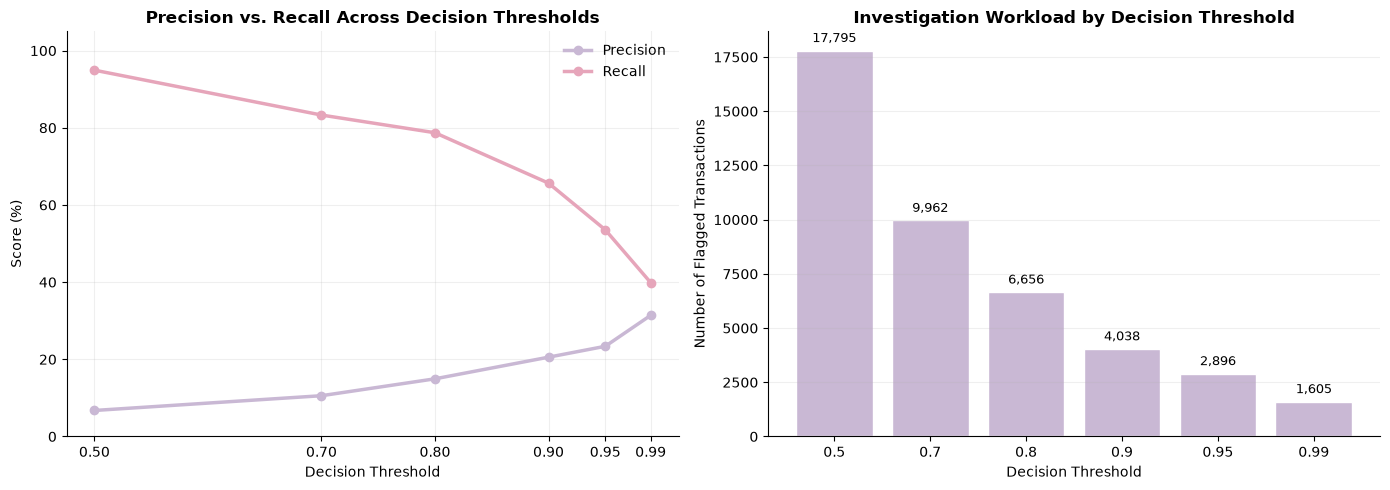

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Precision and Recall
axes[0].plot(
    threshold_comparison["threshold"],
    threshold_comparison["precision"] * 100,
    marker="o",
    linewidth=2.5,
    color="#C9B8D4",
    label="Precision",
)

axes[0].plot(
    threshold_comparison["threshold"],
    threshold_comparison["recall"] * 100,
    marker="o",
    linewidth=2.5,
    color="#E6A5BA",
    label="Recall",
)

axes[0].set_title(
    "Precision vs. Recall Across Decision Thresholds",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Decision Threshold")
axes[0].set_ylabel("Score (%)")
axes[0].set_ylim(0, 105)
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.2)

# Plot 2: Alert Volume
bars = axes[1].bar(
    threshold_comparison["threshold"].astype(str),
    threshold_comparison["alerts"],
    color="#C9B8D4",
    edgecolor="white",
)

axes[1].set_title(
    "Investigation Workload by Decision Threshold",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Decision Threshold")
axes[1].set_ylabel("Number of Flagged Transactions")
axes[1].grid(axis="y", alpha=0.2)

for bar in bars:
    axes[1].annotate(
        f"{bar.get_height():,.0f}",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
        ),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 4),
        textcoords="offset points",
    )

sns.despine()

# Display only the evaluated decision thresholds
axes[0].set_xticks(threshold_comparison["threshold"])
axes[0].set_xticklabels(
    [f"{t:.2f}" for t in threshold_comparison["threshold"]]
)

plt.tight_layout()
plt.show()



### Findings & Modeling Decisions

The decision threshold analysis highlights a substantial trade-off between fraud detection effectiveness and operational workload.

**Key Findings**

1. **High recall comes at a significant operational cost.** At a threshold of 0.50, the model detects 94.94% of fraudulent transactions but generates 17,795 alerts, of which 16,595 are false positives.

2. **Increasing the threshold improves alert precision.** Precision rises from 6.74% at a threshold of 0.50 to 20.55% at 0.90, indicating that a larger proportion of investigated transactions are genuinely fraudulent.

3. **Reducing alert volume also reduces fraud coverage.** Raising the threshold from 0.50 to 0.90 decreases investigation workload by approximately 77.3%, but results in 370 additional missed fraud cases.

4. **Very restrictive thresholds may sacrifice excessive recall.** At 0.99, the model generates only 1,605 alerts and achieves 31.40% precision, but captures just 39.87% of fraudulent transactions.

**Business Implications**

The default threshold of 0.50 prioritizes fraud detection but may overwhelm an investigation team with false-positive alerts. Conversely, higher thresholds reduce workload while allowing more fraudulent transactions to go undetected.

These results suggest that threshold selection should reflect the institution's investigation capacity, tolerance for missed fraud, and relative costs of false positives and false negatives.

**Modeling Decision**

No final threshold is selected at this stage. Instead, the next analysis will evaluate model performance under fixed investigation budgets using Precision@K and Recall@K.

This approach will help determine how effectively FinGuard AI prioritizes the highest-risk transactions when investigation resources are limited.



### 5.4. Operational Evaluation — Fixed Alert Budgets

In real-world fraud detection systems, investigation capacity is often limited. A model may achieve high recall while generating more alerts than a fraud operations team can realistically review.

To evaluate performance under operational constraints, validation transactions are ranked by their predicted fraud risk scores.

We then simulate three hypothetical investigation budgets:

- **0.5%** of transactions reviewed.
- **1.0%** of transactions reviewed.
- **2.0%** of transactions reviewed.

For each budget, we calculate:

- **Precision@K:** The proportion of selected transactions that are fraudulent.
- **Recall@K:** The proportion of all fraudulent transactions captured among the selected transactions.
- **Alert volume:** The number of transactions requiring investigation.

This analysis evaluates the model's ability to prioritize high-risk transactions rather than relying exclusively on a fixed classification threshold.

The investigation budgets are illustrative and do not represent an actual financial institution's operational capacity.


In [32]:

import numpy as np
import pandas as pd

# Rank validation transactions by predicted fraud risk
ranked_indices = np.argsort(-val_probabilities, kind="stable")

y_val_array = y_val.to_numpy()
total_frauds = int(y_val_array.sum())
total_transactions = len(y_val_array)

alert_budgets = [0.005, 0.01, 0.02]

budget_results = []

for budget in alert_budgets:
    n_alerts = int(np.ceil(total_transactions * budget))

    # Select the highest-risk transactions
    selected_indices = ranked_indices[:n_alerts]
    detected_frauds = int(y_val_array[selected_indices].sum())

    budget_results.append({
        "alert_budget_pct": budget * 100,
        "alerts": n_alerts,
        "frauds_detected": detected_frauds,
        "precision_at_k": detected_frauds / n_alerts,
        "recall_at_k": detected_frauds / total_frauds,
    })

budget_comparison = pd.DataFrame(budget_results)

display(
    budget_comparison.style.format({
        "alert_budget_pct": "{:.1f}%",
        "alerts": "{:,.0f}",
        "frauds_detected": "{:,.0f}",
        "precision_at_k": "{:.2%}",
        "recall_at_k": "{:.2%}",
    })
)


,alert_budget_pct,alerts,frauds_detected,precision_at_k,recall_at_k
0,0.5%,"1,099",424,38.58%,33.54%
1,1.0%,"2,197",594,27.04%,46.99%
2,2.0%,"4,393",864,19.67%,68.35%


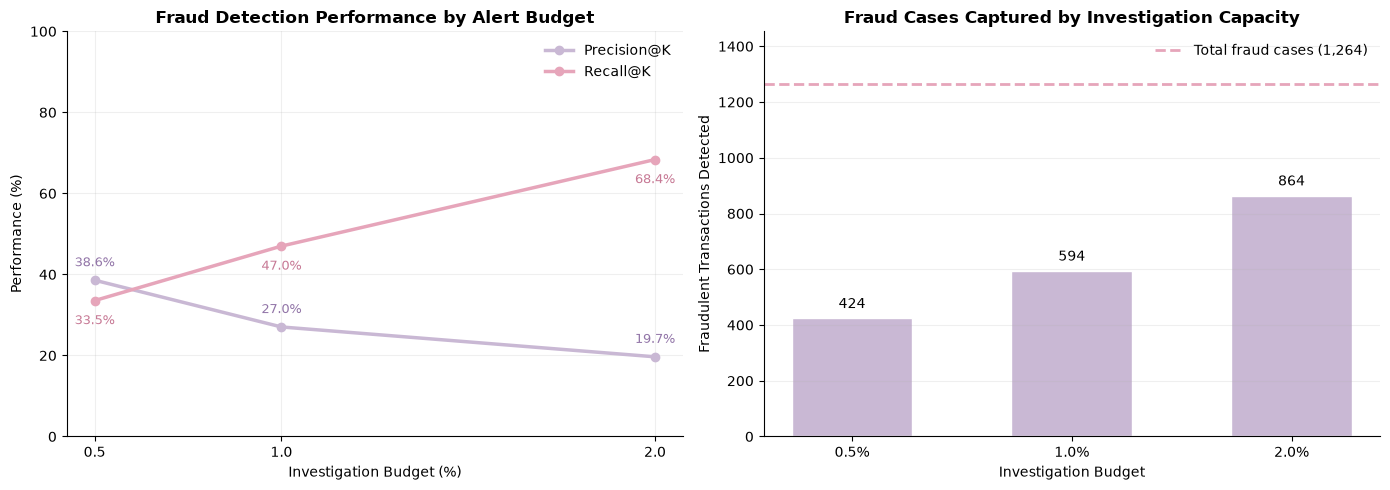

In [33]:

import matplotlib.pyplot as plt
import numpy as np

budgets = budget_comparison["alert_budget_pct"].to_numpy()
precision = budget_comparison["precision_at_k"].to_numpy() * 100
recall = budget_comparison["recall_at_k"].to_numpy() * 100
detected = budget_comparison["frauds_detected"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Precision@K and Recall@K
axes[0].plot(
    budgets, precision,
    marker="o", linewidth=2.5,
    color="#C9B8D4", label="Precision@K"
)
axes[0].plot(
    budgets, recall,
    marker="o", linewidth=2.5,
    color="#E6A5BA", label="Recall@K"
)

axes[0].set_title(
    "Fraud Detection Performance by Alert Budget",
    fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Investigation Budget (%)")
axes[0].set_ylabel("Performance (%)")
axes[0].set_xticks(budgets)
axes[0].set_ylim(0, 100)
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.2)

# Plot 2: Captured Fraud Cases
bars = axes[1].bar(
    [f"{b:.1f}%" for b in budgets],
    detected,
    color="#C9B8D4",
    edgecolor="white",
    width=0.55
)

axes[1].axhline(
    total_frauds,
    color="#E6A5BA",
    linestyle="--",
    linewidth=2,
    label=f"Total fraud cases ({total_frauds:,})"
)

for bar in bars:
    axes[1].annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 5),
        textcoords="offset points"
    )

axes[1].set_title(
    "Fraud Cases Captured by Investigation Capacity",
    fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Investigation Budget")
axes[1].set_ylabel("Fraudulent Transactions Detected")
axes[1].set_ylim(0, total_frauds * 1.15)
axes[1].legend(frameon=False)
axes[1].grid(axis="y", alpha=0.2)

# Annotate Precision@K and Recall@K values
for x, p, r in zip(budgets, precision, recall):
    axes[0].annotate(
        f"{p:.1f}%",
        (x, p),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#9275A8",
    )

    axes[0].annotate(
        f"{r:.1f}%",
        (x, r),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#C77995",
    )

sns.despine()
plt.tight_layout()
plt.show()



### Findings & Modeling Decisions

The fixed alert budget analysis demonstrates that the Logistic Regression baseline can prioritize fraudulent transactions within a limited investigation capacity.

**Key Findings**

1. **Fraud concentration among high-risk transactions.** Reviewing only the highest-risk 0.5% of transactions captures 424 fraud cases (33.54% recall), with a precision of 38.58%.

2. **Meaningful detection under a 1% investigation budget.** Reviewing 2,197 transactions captures 594 of the 1,264 fraud cases, achieving 46.99% recall and 27.04% precision.

3. **Higher investigation capacity improves fraud coverage.** Increasing the budget to 2% captures 864 fraud cases (68.35% recall), although precision decreases to 19.67%.

4. **Strong enrichment over the validation base rate.** At a 1% investigation budget, precision is approximately 47 times the overall fraud prevalence of 0.576%. This indicates meaningful risk ranking within the validation dataset.

**Business Implications**

The results suggest that risk-based transaction prioritization may provide a more operationally useful approach than relying on a default classification threshold.

Increasing investigation capacity improves fraud coverage, but introduces additional review workload and a lower proportion of confirmed fraud among alerts.

**Modeling Decisions**

- Retain Precision@K and Recall@K as operational evaluation metrics.
- Use fixed alert budgets to compare future candidate models on the same validation partition.
- Avoid selecting a final investigation budget without explicit operational and cost assumptions.
- Preserve the chronological test partition for final out-of-time evaluation.

These findings establish a baseline for assessing whether more advanced models and engineered features improve fraud prioritization.
